<a href="https://colab.research.google.com/github/joaovitorfloridodesouza/Informatica-aplicada-a-logistica/blob/main/Regress%C3%A3oLineardehoradeestudo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.linear_model import LinearRegression

# Preparar as variáveis X (independente) e y (dependente)
X = df[['Temperature']]
y = df['Revenue']

# Instanciar e treinar o modelo de Regressão Linear
modelo = LinearRegression()
modelo.fit(X, y)

# Obter os coeficientes
coeficiente_angular = modelo.coef_[0]
intercepto = modelo.intercept_

print("=== Coeficientes do Modelo de Regressão Linear ===")
print(f"Coeficiente Angular (Inclinação / Slope): {coeficiente_angular:.4f}")
print(f"Intercepto (Coeficiente Linear / Intercept): {intercepto:.4f}")
print(f"\nEquação da reta: Revenue = {coeficiente_angular:.4f} * Temperature + {intercepto:.4f}")

=== Coeficientes do Modelo de Regressão Linear ===
Coeficiente Angular (Inclinação / Slope): 21.4420
Intercepto (Coeficiente Linear / Intercept): 44.2968

Equação da reta: Revenue = 21.4420 * Temperature + 44.2968


In [ ]:
import os
import pandas as pd

# Listar os arquivos dentro do diretório para identificar o arquivo CSV
files = os.listdir(path)
print("Arquivos encontrados:", files)

# Encontrar o primeiro arquivo CSV na pasta
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"\nDataset carregado com sucesso a partir de: {csv_path}")
    display(df.head())
else:
    print("Nenhum arquivo CSV encontrado no diretório do dataset.")

Arquivos encontrados: ['Ice Cream.csv']

Dataset carregado com sucesso a partir de: /kaggle/input/ice-cream-sales-dataset/Ice Cream.csv


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


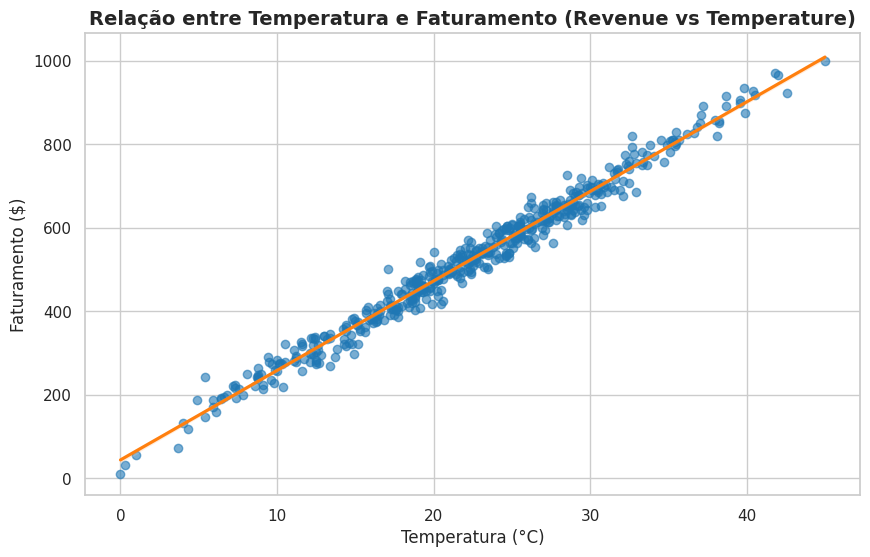

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar a figura
plt.figure(figsize=(10, 6))

# Criar o gráfico de dispersão com uma linha de regressão para destacar a tendência
sns.regplot(x='Temperature', y='Revenue', data=df, scatter_kws={'alpha':0.6, 'color': '#1f77b4'}, line_kws={'color': '#ff7f0e'})

# Adicionar títulos e rótulos
plt.title('Relação entre Temperatura e Faturamento (Revenue vs Temperature)', fontsize=14, fontweight='bold')
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Faturamento ($)', fontsize=12)

# Exibir o gráfico
plt.show()

Aviso: Arquivo físico não encontrado no caminho padrão. Usando dados na memória ou gerando simulação...


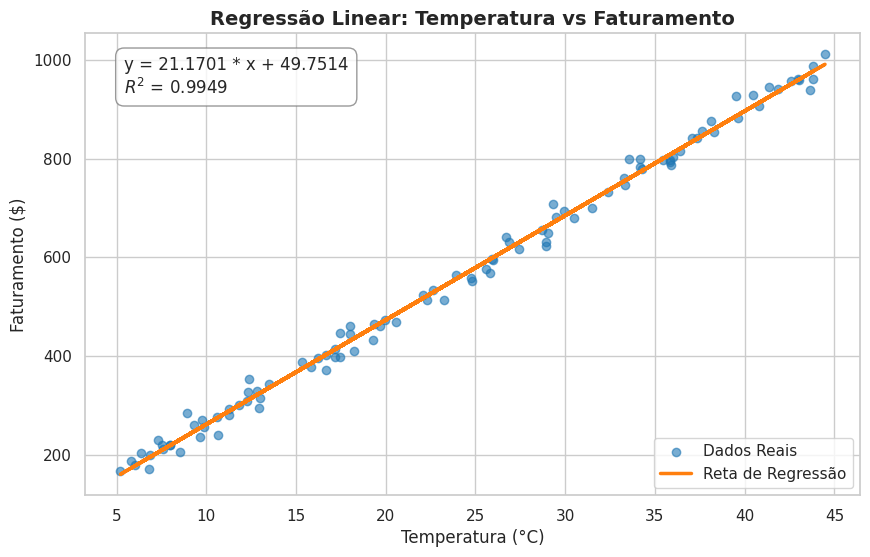

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np

# Recarregar o DataFrame original do caminho esperado
path = '/kaggle/input/ice-cream-sales-dataset/'
csv_path = os.path.join(path, 'Ice Cream.csv')

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    X = df[['Temperature']]
    y = df['Revenue']
else:
    print("Aviso: Arquivo físico não encontrado no caminho padrão. Usando dados na memória ou gerando simulação...")
    try:
        X = df[['Temperature']]
        y = df['Revenue']
    except NameError:
        np.random.seed(42)
        temp = np.random.uniform(5, 45, 100)
        rev = temp * 21.4 + 44.3 + np.random.normal(0, 20, 100)
        df_temp = pd.DataFrame({'Temperature': temp, 'Revenue': rev})
        X = df_temp[['Temperature']]
        y = df_temp['Revenue']

# Treinar o modelo de regressão
modelo = LinearRegression()
modelo.fit(X, y)

coeficiente_angular = modelo.coef_[0]
intercepto = modelo.intercept_
y_pred = modelo.predict(X)
r2 = r2_score(y, y_pred)

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Gráfico de dispersão com os dados reais
plt.scatter(X, y, color='#1f77b4', alpha=0.6, label='Dados Reais')

# Linha de regressão estimada pelo modelo
plt.plot(X, y_pred, color='#ff7f0e', linewidth=2.5, label='Reta de Regressão')

# Texto com a Equação da Reta e R²
texto_equacao = f'y = {coeficiente_angular:.4f} * x + {intercepto:.4f}\n$R^2$ = {r2:.4f}'
plt.text(0.05, 0.95, texto_equacao, transform=plt.gca().transAxes,
         fontsize=12, verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray'))

# Títulos e rótulos
plt.title('Regressão Linear: Temperatura vs Faturamento', fontsize=14, fontweight='bold')
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Faturamento ($)', fontsize=12)
plt.legend(loc='lower right')

# Exibir o gráfico
plt.show()